In [6]:
import numpy as np

def read_txt(file_path):
    data = {}
    # Skip the first few rows start with "#"
    # Then the first row is the header, and the rest are data
    with open(file_path, 'r') as f:
        lines = f.readlines()
        header = None
        for line in lines:
            if line.startswith('#'):
                continue
            if header is None:
                header = line.strip().split("\t")
                for h in header:
                    data[h] = []
            else:
                values = line.strip().split()
                for h, v in zip(header, values):
                    data[h].append(float(v))
    # Convert lists to numpy arrays
    if header is None:
        return data
    for h in header:
        data[h] = np.array(data[h])
    return data

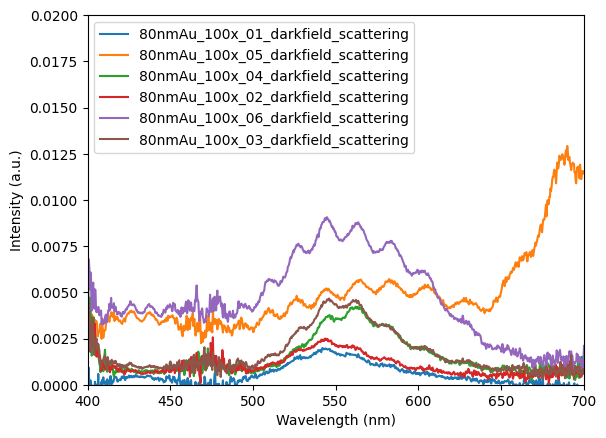

In [12]:
import os
import matplotlib.pyplot as plt

folder = '../assets/data/Au80nm'

wavelengths = {}
intensities = {}

for txt_file in os.listdir(folder):
    if txt_file.endswith('.txt'):
        file_path = os.path.join(folder, txt_file)
        data = read_txt(file_path)
        intensity_key_name = list(data.keys())[1]
        wavelengths[txt_file.rstrip('.txt')] = data['wavelength_nm']
        intensities[txt_file.rstrip('.txt')] = data[intensity_key_name]

fig, ax = plt.subplots()
for key in wavelengths.keys():
    ax.plot(wavelengths[key], intensities[key], label=key)
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Intensity (a.u.)')
ax.set_xlim(400, 700)
ax.set_ylim(0, 0.02)
ax.legend()